# 01 — Benchmark figures

Figures 2a–c and S1a–g are generated from the validated outputs of benchmarking scripts s01–s04 and s06. Each section states the benchmark question, shows the results used, and draws the corresponding manuscript panel. Figure S2 will be added after s05 is verified.

The notebook only reads `results/01_benchmarks/`. It does not run scCHART or modify numerical results.

## Setup

Results are read from the public repository. The display settings retain the manuscript's typography, colours and dimensions. Coordinates in the rendering functions are measured in millimetres so that the panel layout stays consistent with the source artwork.

In [1]:
# Publication layout: millimetres, Arial, editable vector text.
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, ConnectionPatch, Rectangle
from matplotlib.colors import Normalize
from matplotlib.transforms import Bbox
from IPython.display import display, Image
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json

MM = 1 / 25.4
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = 8, 7, 6, 6, 5.5, 5
LW_AX, LW_DATA = 0.5, 1.0
STRUCT, STRUCT_L = "#3A4F8C", "#A9BCD0"
PROG, PROG_L = "#2A9070", "#9FD3C7"
INK, MUTED, GUIDE = "#1A1A1A", "#555555", "#C8C8C8"
NEUTRAL_L = "#BDBDBD"

def apply_style() -> None:
    """Matplotlib settings of the frozen figures (Arial, 5-8 pt, editable text in SVG/PDF)."""
    import matplotlib._mathtext as mathtext
    mathtext.SHRINK_FACTOR = 0.84            # sub/superscripts of 6 pt text stay >= 5 pt
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"], "font.size": FS_TICK,
        "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold", "mathtext.sf": "Arial", "mathtext.default": "it",
        "axes.labelsize": FS_LABEL, "axes.titlesize": FS_LABEL, "axes.titlepad": 3,
        "axes.linewidth": LW_AX, "axes.edgecolor": INK, "axes.labelcolor": INK, "axes.labelpad": 2,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "xtick.major.width": LW_AX,
        "ytick.major.width": LW_AX, "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5,
        "ytick.major.pad": 1.5, "xtick.color": INK, "ytick.color": INK,
        "legend.fontsize": FS_ANN, "legend.frameon": False, "legend.handletextpad": 0.4,
        "legend.borderaxespad": 0.2, "legend.labelspacing": 0.25,
        "lines.linewidth": LW_DATA, "lines.markersize": 2.6, "errorbar.capsize": 0,
        "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
        "figure.facecolor": "white", "savefig.facecolor": "white",
    })

class Canvas:
    """A figure laid out in millimetres, origin at the top-left corner."""

    def __init__(self, width_mm: float, height_mm: float):
        import matplotlib.pyplot as plt
        self.fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
        # Matplotlib rounds the figure size to whole pixels (183 mm -> 7.2 in); positions are computed from the
        # realised size, as in the frozen figures, so element coordinates match them exactly.
        self.W, self.H = (v / MM for v in self.fig.get_size_inches())

    def ax(self, x, y, w, h, **kw):
        return self.fig.add_axes([x / self.W, 1 - (y + h) / self.H, w / self.W, h / self.H], **kw)

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", FS_ANN); kw.setdefault("va", "top"); kw.setdefault("color", INK)
        return self.fig.text(x / self.W, 1 - y / self.H, s, **kw)

    def letter(self, x, y, s):
        return self.text(x, y, s, fontsize=FS_LETTER, fontweight="bold", ha="left")

    def legend_at(self, handles, x, y, **kw):
        """Figure legend whose top centre is at (x, y) mm."""
        return self.fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x / self.W, 1 - y / self.H),
                               borderaxespad=0, **kw)

class Region:
    """A panel region of a Canvas: the same placement calls, in mm relative to the region's top-left corner."""

    def __init__(self, cv: Canvas, x0: float, y0: float):
        self.cv, self.x0, self.y0, self.fig = cv, x0, y0, cv.fig

    def ax(self, x, y, w, h, **kw):
        return self.cv.ax(self.x0 + x, self.y0 + y, w, h, **kw)

    def text(self, x, y, s, **kw):
        return self.cv.text(self.x0 + x, self.y0 + y, s, **kw)

    def letter(self, s):
        return self.cv.letter(self.x0, self.y0, s)

    def head(self, x, y, s, w=None, color=None, fontsize=None):
        """Bold section heading, optionally underlined by a guide rule of width w mm."""
        self.text(x, y, s, fontsize=fontsize or FS_ANN, fontweight="bold", color=color or INK)
        if w:
            a = self.ax(x, y + 3.4, w, 0.4); a.set_xlim(0, 1); a.set_ylim(0, 1); blank(a)
            a.plot([0, 1], [0.5, 0.5], c=GUIDE, lw=0.5)

def blank(ax) -> None:
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

def format_value(panel, quantity, exact, fmt, source="", flag=False):
    """Format a value computed by the benchmark scripts; never substitute frozen numbers."""
    return fmt(exact) if callable(fmt) else format(exact, fmt) if fmt else str(exact)


def save_figure(fig, name):
    """Export an entire manuscript figure as vector PDF/SVG and 300-dpi PNG."""
    for ext, kw in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = FIG / f"{name}.{ext}"
        fig.savefig(path, **kw)
        print(path.relative_to(ROOT))


def save_region(cv, region, name):
    """Save one panel of a separately drawn figure, with room for insets and legends."""
    x, y, width, height = region
    crop = Bbox.from_bounds(x * MM, (cv.H - y - height) * MM, width * MM, height * MM)
    for ext, kw in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = FIG / f"{name}.{ext}"
        cv.fig.savefig(path, bbox_inches=crop, pad_inches=0, **kw)
        print(path.relative_to(ROOT))

apply_style()

In [2]:
# Run from the repository root or its notebooks/ directory.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "scripts" / "01_benchmarks").is_dir(), "Open this notebook from scCHART_analysis or notebooks/"
RES = ROOT / "results" / "01_benchmarks"
FIG = ROOT / "figures" / "01_benchmarks"
FIG.mkdir(parents=True, exist_ok=True)

def read_table(filename, columns, expected_rows=None):
    path = RES / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing validated benchmark output: {path}")
    frame = pd.read_csv(path, sep="\t")
    missing = set(columns) - set(frame.columns)
    assert not missing, f"{filename}: missing columns {sorted(missing)}"
    if expected_rows is not None:
        assert len(frame) == expected_rows, f"{filename}: {len(frame)} rows, expected {expected_rows}"
    return frame

print("Benchmark results:", RES)
print("Figure output:", FIG)

Benchmark results: /Users/arvind/Documents/postdoc/hetrogenity_new/scehr_recomb2027_manuscript/manuscript_v2/scChart_reproduciblity/scCHART_analysis/results/01_benchmarks
Figure output: /Users/arvind/Documents/postdoc/hetrogenity_new/scehr_recomb2027_manuscript/manuscript_v2/scChart_reproduciblity/scCHART_analysis/figures/01_benchmarks


## Figure 2a — Structural heterogeneity

**Question.** Does structural heterogeneity increase as cell populations become more dispersed or as two equally represented states separate?

**Design.** The structural benchmark varies continuous dispersion or the distance between two states while evaluating population-level structural divergence. Dots are replicate populations; the lines summarize their means. Small scatterplots show the simulated state geometry for selected settings.

In [3]:
W, H = 183, 152                                   # mm, as the frozen figure
AX = 34.0                                         # every plot area is AX x AX mm
TOP_AXL = [c + 10.5 for c in (0, 45.75, 91.5, 137.25)]
TOP_Y = 32.0
BOT_AXL = [c + 17.0 for c in (0, 61, 122)]
BOT_Y = 100.0
ROW1, ROW2 = 0.0, 79.0
FIG2_REGIONS = {"a": (0, ROW1, 91.5, 77), "b": (91.5, ROW1, 91.5, 77), "c": (0, ROW2, 61, H - ROW2),
                 "d": (61, ROW2, 61, H - ROW2), "e": (122, ROW2, 61, H - ROW2)}      # x, y, w, h in mm

# s01: structural dispersion/separation; s02: programme specialisation; s04: real-cell mixtures.
B1 = "results/01_benchmarks/"  # annotation source only; actual reads use RES
A_rep = read_table("structural_benchmark_replicates.tsv", ["benchmark", "level", "J_obs"], 260)
A_sum = read_table("structural_benchmark_summary.tsv", ["benchmark", "level", "J_obs_mean", "spearman_rho_level_J_obs"], 13)
A_view = read_table("structural_benchmark_views.tsv", ["benchmark", "level", "axis_state", "axis_orth", "true_state"], 2000)
B_rep = read_table("programme_benchmark_replicates.tsv", ["delta_p", "Delta_P", "median_P"], 100)
B_sum = read_table("programme_benchmark_summary.tsv", ["delta_p", "Delta_P_mean", "median_P_mean"], 5)
C_rep = read_table("mixture_replicates.tsv", ["k", "Delta_S", "Delta_P"], 310)
C_k = read_table("mixture_summary_by_k.tsv", ["score", "k", "mean", "sd"])
C_sel = read_table("mixture_population_selection.tsv", ["population", "selected"])
MIX_POPS = [("12_CD14.Mono.2", "CD14.Mono.2", "#E69F00"), ("22_CD4.M", "CD4.M", "#56B4E9"), ("17_B", "B", "#CC79A7"),
            ("25_NK", "NK", "#009E73"), ("09_pDC", "pDC", "#7A1F5C")]
assert sorted(C_sel.population[C_sel.selected]) == sorted(p for p, _, _ in MIX_POPS)

In [4]:
def arrow_h(cv, x0, y, x1, label=None):
    a = cv.ax(x0, y - 1.5, x1 - x0, 3)
    a.set_xlim(0, 1)
    a.set_ylim(0, 1)
    blank(a)
    a.annotate('', xy=(1, 0.5), xytext=(0, 0.5), arrowprops=dict(arrowstyle='-|>', color=MUTED, lw=0.6, mutation_scale=6))
    if label:
        cv.text((x0 + x1) / 2, y - 1.6, label, ha='center', va='bottom', fontsize=FS_SMALL, color=MUTED)

def title(cv, axl, y, s, color=INK, sub=None):
    cv.text(axl + AX / 2, y, s, ha='center', fontsize=FS_ANN, fontweight='bold', color=color, linespacing=1.15)
    if sub:
        cv.text(axl + AX / 2, y + 3.0, sub, ha='center', fontsize=FS_SMALL, linespacing=1.15)

def inset_cloud(ax, bench, level):
    v = A_view[(A_view.benchmark == bench) & np.isclose(A_view.level, level)]
    if bench == 'two_state':
        for state, c in (('A', STRUCT), ('B', '#8FA6D6')):
            w = v[v.true_state == state]
            ax.scatter(w.axis_orth, w.axis_state, s=0.45, c=c, lw=0)
        ax.set(xlim=(-0.5, 0.5), ylim=(-1.75, 1.75))
    else:
        ax.scatter(v.axis_orth, v.axis_state, s=0.45, c=STRUCT, lw=0)
        ax.set(xlim=(-0.5, 0.5), ylim=(-0.5, 0.5))
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_color(GUIDE)
        s.set_linewidth(0.4)

def panel_a(cv):
    TH = 9.0
    specs = [(0, 'continuous_dispersion', (0.05, 0.8), 'h', 'Continuous dispersion', 'Dispersion, h', [0, 0.4, 0.8], (-0.05, 0.85), 'continuous dispersion'), (1, 'two_state', (0.0, 3.0), 'δ', 'Two balanced states', 'Separation of 50:50 states, δ', [0, 1, 2, 3], (-0.18, 3.18), 'two balanced states')]
    for col, bench, levs, sym, ttl, xl, xt, xlim, key in specs:
        axl = TOP_AXL[col]
        title(cv, axl, ROW1 + 0.4, ttl, sub='500 cells per population')
        ax = cv.ax(axl, TOP_Y, AX, AX)
        ax.patch.set_alpha(0)
        r, s = (A_rep[A_rep.benchmark == bench], A_sum[A_sum.benchmark == bench].sort_values('level'))
        jit = (np.random.default_rng(0).random(len(r)) - 0.5) * 0.025 * r.level.max()
        ax.scatter(r.level + jit, r.J_obs, s=1.5, c=STRUCT_L, lw=0, zorder=1)
        ax.plot(s.level, s.J_obs_mean, '-o', c=STRUCT, ms=2.2, lw=1, zorder=2)
        ax.set(xlabel=xl, xticks=xt, xlim=xlim, ylim=(-0.03, 1.08), yticks=[0, 0.5, 1])
        ax.set_ylabel('Structural $J_G^{(S)}$ (bits)')
        src = B1 + 'structural_benchmark_summary.tsv / _replicates.tsv'
        rho = format_value('a', f'{key}: Spearman rho', float(s.spearman_rho_level_J_obs.iloc[0]), '.2f', src)
        n = format_value('a', f'{key}: replicate observations', len(r), 'd', src)
        ax.text(0.98, 0.03, f'Spearman correlation:\nρ = {rho}\nReplicate observations:\nn = {n}', transform=ax.transAxes, ha='right', va='bottom', fontsize=FS_MIN, linespacing=1.25)
        centres = []
        for lev in levs:
            xc = axl + (lev - xlim[0]) / (xlim[1] - xlim[0]) * AX
            xc = min(max(xc, axl - 3.0), axl + AX + 2.0)
            a = cv.ax(xc - TH / 2, 11.5, TH, TH)
            inset_cloud(a, bench, lev)
            a.set_title(f'{sym} = {lev:g}', fontsize=FS_SMALL, pad=1.2)
            yv = float(s.loc[np.isclose(s.level, lev), 'J_obs_mean'].iloc[0])
            ax.scatter([lev], [yv], s=22, facecolors='none', edgecolors=MUTED, lw=0.6, zorder=3)
            cv.fig.add_artist(ConnectionPatch(xyA=(0.5, 0), coordsA=a.transAxes, xyB=(lev, yv), coordsB=ax.transData, color=MUTED, lw=0.5, ls=(0, (1.2, 1.2)), shrinkB=2.6, zorder=1))
            centres.append(xc)
        arrow_h(cv, centres[0] + TH / 2 + 1.2, 16.0, centres[1] - TH / 2 - 1.2)

figures/01_benchmarks/Figure2a.pdf
figures/01_benchmarks/Figure2a.svg
figures/01_benchmarks/Figure2a.png


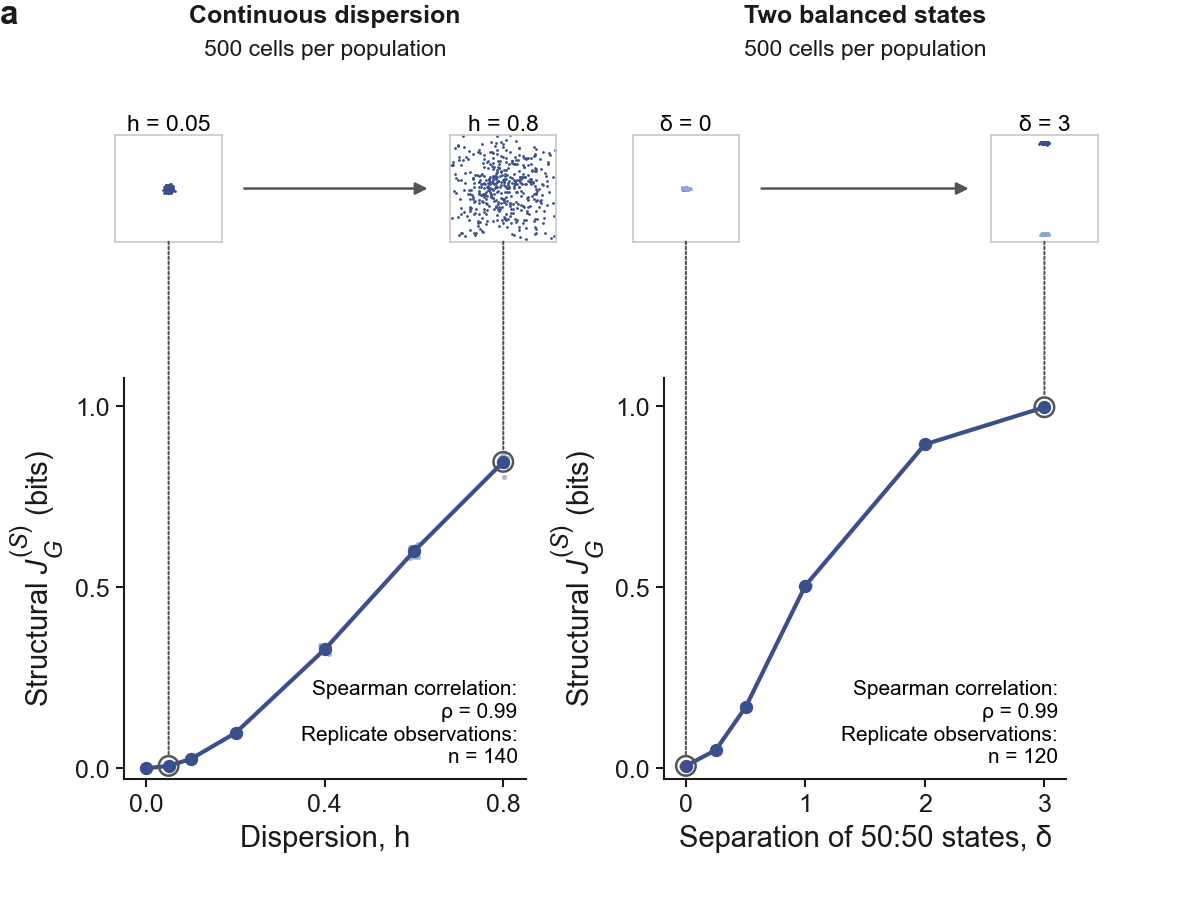

In [5]:
# Draw only panel 2a, so its inset can extend beyond the nominal 91.5 mm panel boundary.
canvas = Canvas(W, H)
panel_a(canvas)
canvas.letter(0, 0, "a")
save_region(canvas, (0, 0, 100, 77), "Figure2a")
display(Image(filename=str(FIG / "Figure2a.png")))
plt.close(canvas.fig)

## Figure 2b — Regulatory programme specialisation

**Question.** Can scCHART distinguish differences in programme usage *between cells* from programme diversity *within individual cells*?

**Design.** Programme specialisation is varied in controlled simulations. The left graph shows calibrated between-cell programme heterogeneity; the right graph shows median within-cell programme diversity. Pie charts are conceptual illustrations of programme weights, not measured cell compositions.

In [6]:
PCOL = ["#2A9070", "#E3B04B", "#8C6BB1"]  # three illustrated regulatory programmes

def pies(cv, xc, y0, dp, caption):
    D, pitch = (5.6, 6.6)
    x0 = xc - pitch - D / 2
    for c in range(3):
        a = cv.ax(x0 + c * pitch, y0, D, D)
        w = np.exp(dp * np.eye(3)[c])
        w /= w.sum()
        a.pie(w, colors=PCOL, startangle=90, wedgeprops=dict(lw=0.4, ec='white'))
        a.set_aspect('equal')
        blank(a)
        cv.text(x0 + c * pitch + D / 2, y0 + D + 0.3, f'cell {c + 1}', ha='center', fontsize=FS_MIN, color=MUTED)
    cv.text(xc, ROW1 + 0.4, f'δ$_p$ = {dp:g}', ha='center', fontsize=FS_ANN, fontweight='bold')
    cv.text(xc, ROW1 + 3.9, caption, ha='center', fontsize=FS_SMALL, linespacing=1.15)

def panel_b(cv):
    c1, c2 = (TOP_AXL[2] + AX / 2, TOP_AXL[3] + AX / 2)
    pies(cv, c1, 9.4, 0.0, 'Similar programme mixtures\nacross cells')
    pies(cv, c2, 9.4, 3.0, 'Different programmes\ndominate different cells')
    arrow_h(cv, c1 + 11.5, 12.2, c2 - 11.5, 'δ$_p$ increases')
    x0, x1 = (c1 - 9.6, c2 + 9.6)
    br = cv.ax(x0, 17.6, x1 - x0, 1.4)
    br.set_xlim(0, 1)
    br.set_ylim(0, 1)
    blank(br)
    br.plot([0, 0, 1, 1], [1, 0.3, 0.3, 1], c=MUTED, lw=0.5)
    cv.text((x0 + x1) / 2, 19.5, 'all cells belong to the same declared population $G$', ha='center', fontsize=FS_SMALL, color=MUTED)
    handles = [Line2D([], [], ls='', marker='o', ms=3.0, mfc=c, mec='none', label=f'programme {k + 1}') for k, c in enumerate(PCOL)]
    cv.legend_at(handles, (x0 + x1) / 2, 22.3, ncol=3, fontsize=FS_MIN, handletextpad=0.1, columnspacing=0.8)
    jit = (np.random.default_rng(1).random(len(B_rep)) - 0.5) * 0.14
    a1, a2 = (cv.ax(TOP_AXL[2], TOP_Y, AX, AX), cv.ax(TOP_AXL[3], TOP_Y, AX, AX))
    a1.scatter(B_rep.delta_p + jit, B_rep.Delta_P, s=1.5, c=PROG_L, lw=0)
    a1.plot(B_sum.delta_p, B_sum.Delta_P_mean, '-o', c=PROG, ms=2.2, lw=1)
    a1.axhline(0, c=GUIDE, lw=0.4)
    a1.set(xlabel='Programme difference, δ$_p$', xticks=[0, 1, 2, 3])
    a1.set_ylabel('Programme $Δ_G^{(P)}$ (bits)')
    a2.scatter(B_rep.delta_p + jit, B_rep.median_P, s=1.5, c=NEUTRAL_L, lw=0)
    a2.plot(B_sum.delta_p, B_sum.median_P_mean, '-o', c=INK, ms=2.2, lw=1)
    a2.set(xlabel='Programme difference, δ$_p$', ylim=(0, 1.05), xticks=[0, 1, 2, 3], yticks=[0, 0.5, 1])
    a2.set_ylabel('Median $\\mathcal{P}_i$')
    title(cv, TOP_AXL[2], 25.2, 'Between cells', color=PROG, sub='variation in programme usage across cells')
    title(cv, TOP_AXL[3], 25.2, 'Within cells', sub='diversity of programme usage in each cell')

1 extra bytes in post.stringData array


figures/01_benchmarks/Figure2b.pdf
figures/01_benchmarks/Figure2b.svg
figures/01_benchmarks/Figure2b.png


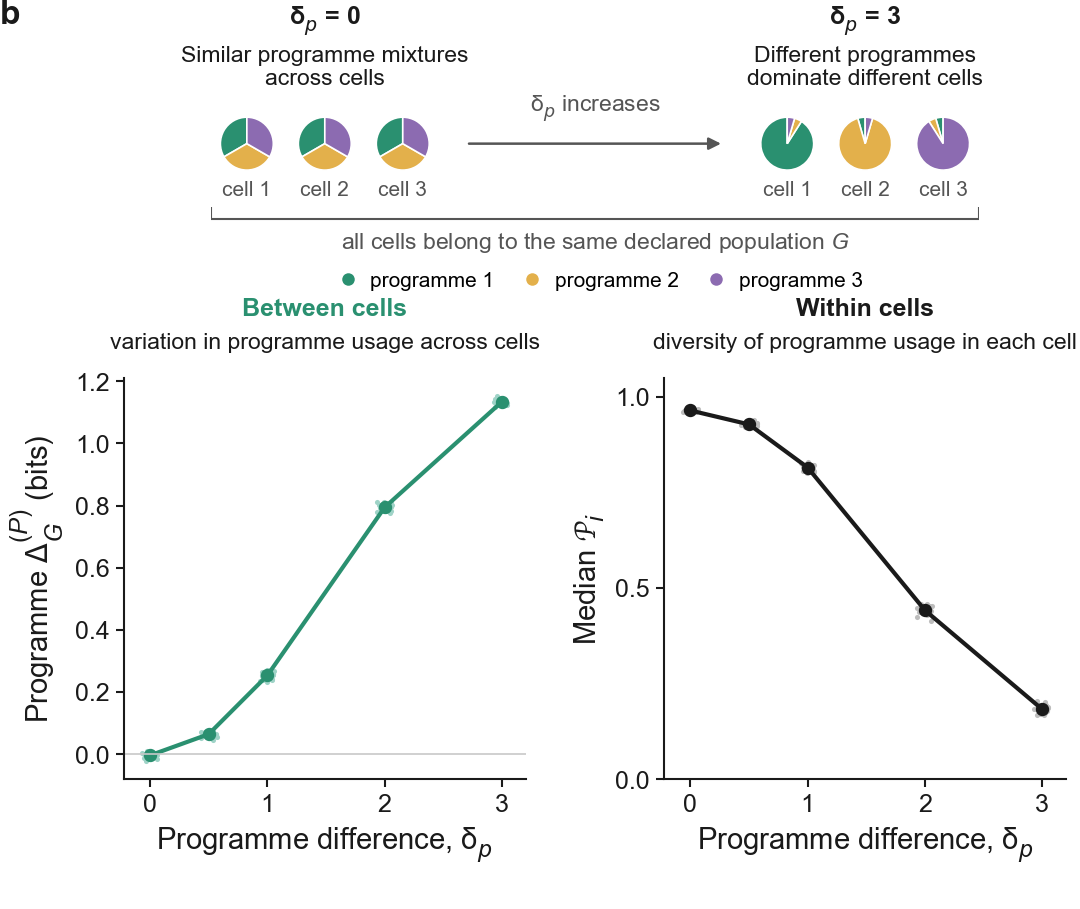

In [7]:
canvas = Canvas(W, H)
panel_b(canvas)
canvas.letter(FIG2_REGIONS["b"][0], 0, "b")
save_region(canvas, FIG2_REGIONS["b"], "Figure2b")
display(Image(filename=str(FIG / "Figure2b.png")))
plt.close(canvas.fig)

## Figure 2c — Mixtures of real haematopoietic populations

**Question.** Does heterogeneity increase when distinct real cell populations are combined?

**Design.** The benchmark samples mixtures of one to five Granja populations (10 replicates per composition), matches depth, and scores both scCHART axes. Dots represent replicates; point-and-error-bar summaries represent means and standard deviations. The circles above the plot illustrate the mixing design.

In [8]:
def arrow_v(cv, x, y0, y1):
    a = cv.ax(x - 1.5, y0, 3, y1 - y0)
    a.set_xlim(0, 1)
    a.set_ylim(1, 0)
    blank(a)
    a.annotate('', xy=(0.5, 1), xytext=(0.5, 0), arrowprops=dict(arrowstyle='-|>', color=MUTED, lw=0.6, mutation_scale=5))

def panel_c(cv):
    axl, XL = (BOT_AXL[0], (0.6, 5.4))
    title(cv, axl, ROW2 + 0.4, 'Mixtures of real\nhematopoietic populations')
    handles = [Line2D([], [], ls='', marker='o', ms=2.8, mfc=c, mec='none', label=n) for _, n, c in MIX_POPS]
    cv.legend_at(handles, axl + AX / 2, BOT_Y + AX + 9.6, ncol=5, fontsize=FS_MIN, handletextpad=0.05, columnspacing=0.6)
    rng = np.random.default_rng(7)
    CY, CD = (ROW2 + 9.6, 6.4)
    for k in range(1, 6):
        xc = axl + (k - XL[0]) / (XL[1] - XL[0]) * AX
        a = cv.ax(xc - CD / 2, CY, CD, CD)
        a.set_xlim(-1.05, 1.05)
        a.set_ylim(-1.05, 1.05)
        blank(a)
        a.set_aspect('equal')
        a.add_patch(Circle((0, 0), 1, fc='white', ec=GUIDE, lw=0.5))
        n = 30 // k * k
        rr, th = (np.sqrt(rng.random(n)) * 0.84, rng.random(n) * 2 * np.pi)
        a.scatter(rr * np.cos(th), rr * np.sin(th), s=0.7, c=np.repeat([c for _, _, c in MIX_POPS[:k]], n // k), lw=0)
        a.set_title(f'k = {k}', fontsize=FS_SMALL, pad=0.8)
        arrow_v(cv, xc, CY + CD + 0.5, BOT_Y - 0.5)
    ax = cv.ax(axl, BOT_Y, AX, AX)
    rng = np.random.default_rng(4)
    for score, c, cl, lab, off in (('Delta_S', STRUCT, STRUCT_L, 'Structural', -0.13), ('Delta_P', PROG, PROG_L, 'Programme', 0.13)):
        ax.scatter(C_rep.k + off + (rng.random(len(C_rep)) - 0.5) * 0.16, C_rep[score], s=1.2, c=cl, lw=0, zorder=1)
        k = C_k[C_k.score == score].sort_values('k')
        ax.errorbar(k.k + off, k['mean'], yerr=k['sd'], fmt='-o', c=c, ms=2.2, lw=1, elinewidth=0.6, zorder=2, label=lab)
    ax.set(xlabel='Populations mixed, k', ylabel='Calibrated excess $Δ_G$ (bits)', xticks=[1, 2, 3, 4, 5], xlim=XL, yticks=[0, 0.5, 1, 1.5])
    ax.legend(loc='lower right', fontsize=FS_SMALL, handlelength=1.6)

figures/01_benchmarks/Figure2c.pdf
figures/01_benchmarks/Figure2c.svg
figures/01_benchmarks/Figure2c.png


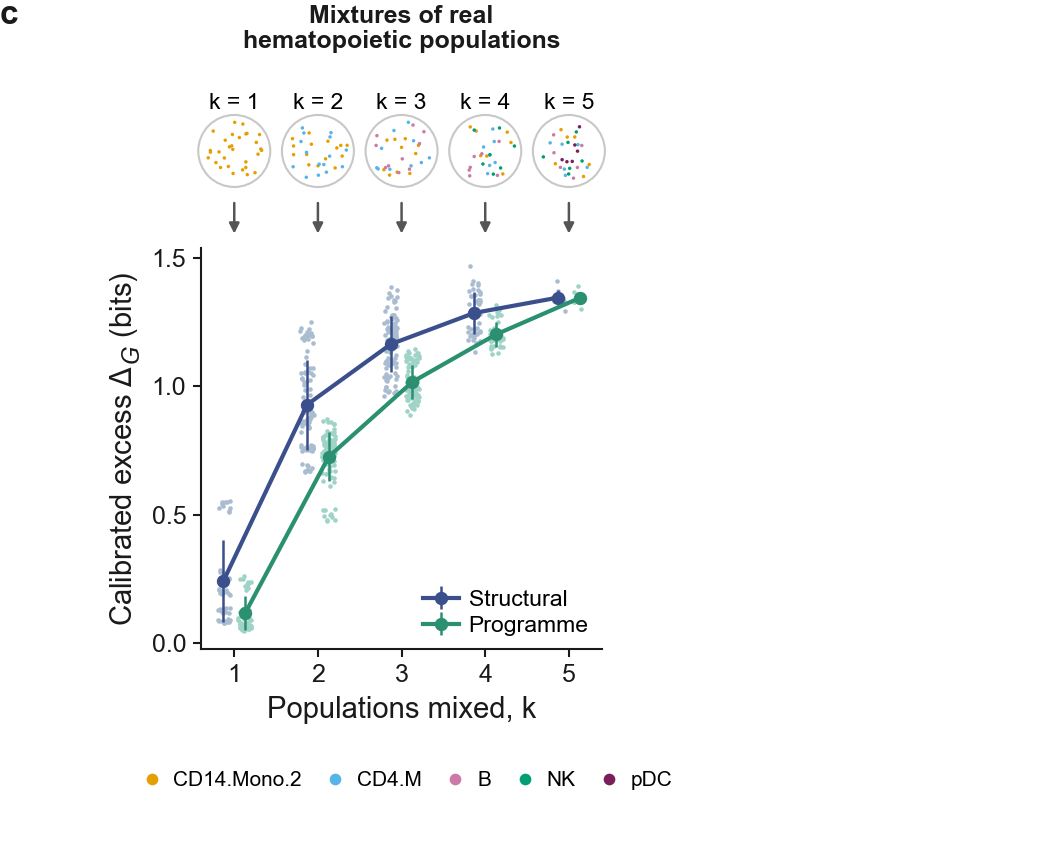

In [9]:
canvas = Canvas(W, H)
panel_c(canvas)
canvas.letter(FIG2_REGIONS["c"][0], FIG2_REGIONS["c"][1], "c")
# Use a slightly wider crop for the multi-column legend; no other panel is drawn on this canvas.
save_region(canvas, (0, 79, 90, 73), "Figure2c")
display(Image(filename=str(FIG / "Figure2c.png")))
plt.close(canvas.fig)

## Supplementary Figure S1 — Benchmark details

Figure S1 combines seven complementary checks using validated outputs from s01, s03, s04 and s06. The following code makes each panel separately understandable before assembling the complete supplementary figure.

In [10]:
SIZE = (183, 244)
PANELS = {"a": (0, 0, 183, 45), "b": (0, 47, 91, 52), "c": (92, 47, 91, 52), "d": (0, 100, 57, 52),
          "e": (57, 100, 57, 52), "f": (115, 100, 68, 52), "g": (0, 154, 183, 90)}
PANEL_REGIONS = PANELS
MIX_POPS = {"CD14.Mono.2": "#E69F00", "CD4.M": "#56B4E9", "B": "#CC79A7", "NK": "#009E73", "pDC": "#7A1F5C"}

# s01, s03, s04, s06: all seven Figure S1 panels.
cells = read_table("structural_benchmark_per_cell.tsv.gz", ["benchmark", "level", "scchart_structural_d"], 130000)
grid = read_table("substate_summary.tsv", ["minority_fraction", "separation", "J_S_mean", "J_S_sd", "Delta_P_mean", "Delta_P_sd"], 35)
au = read_table("introduced_cells_auroc_summary.tsv", ["A", "B", "f", "auroc_mean"], 25)
comp = read_table("mixture_summary_by_composition.tsv", ["composition_id", "composition", "k", "n_replicates", "Delta_S_mean", "Delta_S_sd", "Delta_P_mean", "Delta_P_sd"], 31)
rep = read_table("mixture_replicates.tsv", ["composition_id", "k", "n_cells", "Delta_S", "Delta_P"], 310)
comp = comp.sort_values(["k", "composition_id"]).reset_index(drop=True)
assert (comp.n_replicates == comp.n_replicates.iloc[0]).all()
assert comp.k.value_counts().sort_index().tolist() == [5, 10, 10, 5, 1]
SEPS = sorted(grid.separation.unique())
S06 = json.loads((RES / "s06_introduced_cells.run.json").read_text())
R1 = "results/01_benchmarks/"  # annotation source only

### S1a — Per-cell contributions

Tests whether the cell-level structural contributions track the simulated dispersion and separation gradients. Each violin shows a distribution of individual-cell scores; the horizontal line marks its mean.

In [11]:
def head(P, s, color=None, w=None):
    P.head(5, 0.4, s, color=color, w=w)

def panel_a(P):
    head(P, 'Per-cell structural contributions (no null)')
    groups = [('continuous_dispersion', (0.05, 0.2, 0.4, 0.8), 'Continuous dispersion, h'), ('two_state', (0.5, 1.0, 3.0), 'Separation of two 50:50 states, δ')]
    axes = [P.ax(14, 8, 88, 27), P.ax(116, 8, 62, 27)]
    for ax, (b, levs, xl) in zip(axes, groups):
        for i, lev in enumerate(levs):
            v = cells[(cells.benchmark == b) & np.isclose(cells.level, lev)].scchart_structural_d
            pr = ax.violinplot(v, positions=[i], widths=0.75, showextrema=False)
            for pc in pr['bodies']:
                pc.set_facecolor(STRUCT)
                pc.set_alpha(0.85)
                pc.set_edgecolor('none')
            ax.plot([i - 0.3, i + 0.3], [v.mean()] * 2, c=INK, lw=0.9)
        ax.set_xticks(range(len(levs)), [f'{l:g}' for l in levs])
        ax.set_xlim(-0.6, len(levs) - 0.4)
        ax.set(xlabel=xl, ylim=(-0.1, 4.2), yticks=[0, 1, 2, 3, 4])
    axes[0].set_ylabel('Per-cell contribution $d_i^{(S)}$ (bits)')
    axes[1].set_ylabel('$d_i^{(S)}$ (bits)')
    axes[1].legend(handles=[Line2D([], [], c=INK, lw=0.9, label='Mean = population $J_G^{(S)}$')], loc='upper left', fontsize=FS_SMALL, handlelength=1.4)

### S1b–e — Minority state abundance and separation

These panels show how structural and programme heterogeneity respond to the relative abundance and separation of a minority state. Heatmaps provide the two-dimensional response; line graphs show mean ± standard deviation across replicates.

In [12]:
def heat(P, col, cmap, ttl, cblabel, color):
    head(P, ttl, color=color)
    ax, cax = (P.ax(16, 8, 58, 36), P.ax(77, 8, 2.2, 36))
    piv = grid.pivot(index='separation', columns='minority_fraction', values=col).sort_index(ascending=False)
    vmax = np.nanmax(piv.values)
    im = ax.imshow(piv.values, cmap=cmap, aspect='auto', norm=Normalize(min(0, np.nanmin(piv.values)), vmax))
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=FS_MIN, color='white' if v > 0.55 * vmax else INK)
    ax.set_xticks(range(piv.shape[1]), [f'{100 * v:g}' for v in piv.columns])
    ax.set_yticks(range(piv.shape[0]), [f'{v:g}' for v in piv.index])
    ax.set(xlabel='Minority state (% of cells)', ylabel='State separation')
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = P.fig.colorbar(im, cax=cax)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=FS_TICK, length=1.5)
    cb.set_label(cblabel, fontsize=FS_ANN)

def panel_b(P):
    heat(P, 'J_S_mean', 'Blues', 'Structural: abundance × separation', 'Structural $J_G^{(S)}$ (bits; no null)', STRUCT)

def panel_c(P):
    heat(P, 'Delta_P_mean', 'Greens', 'Programme: abundance × separation', 'Programme $Δ_G^{(P)}$ (bits; calibrated)', PROG)

def response(P, col, sdcol, cmap, ttl, ylab, color, legend):
    head(P, ttl, color=color)
    ax = P.ax(13, 9, 41, 34)
    cm = plt.get_cmap(cmap)
    for k, s in enumerate(SEPS):
        d = grid[np.isclose(grid.separation, s)].sort_values('minority_fraction')
        c = GUIDE if s == 0 else cm(0.35 + 0.65 * k / (len(SEPS) - 1))
        ax.errorbar(100 * d.minority_fraction, d[col], yerr=d[sdcol], fmt='-o', c=c, ms=1.8, lw=0.9, elinewidth=0.5, label=f'{s:g}')
    ax.set(xlabel='Minority state (% of cells)', ylabel=ylab, xticks=[0, 10, 20, 30, 40, 50])
    if legend:
        ax.legend(title='Separation', title_fontsize=FS_SMALL, fontsize=FS_SMALL, loc='upper left', handlelength=1.2, borderaxespad=0.2, labelspacing=0.25)

def panel_d(P):
    response(P, 'J_S_mean', 'J_S_sd', 'Blues', 'Structural response', 'Structural $J_G^{(S)}$ (bits; no null)', STRUCT, True)

def panel_e(P):
    response(P, 'Delta_P_mean', 'Delta_P_sd', 'Greens', 'Programme response', 'Programme $Δ_G^{(P)}$ (bits; calibrated)', PROG, False)

### S1f — Detection of introduced cells

The AUROC benchmark evaluates whether per-cell structural divergence identifies introduced cells from a second Buenrostro population. AUROC = 0.5 denotes chance-level discrimination. We retain the verified s06 values without rerunning the mixtures.

In [13]:
PAIRS = [
    ("HSC", "mono", "#7B3F72"),
    ("HSC", "MEP", "#B2443A"),
    ("GMP", "MEP", "#D08C2E"),
    ("CMP", "LMPP", "#3B5B7E"),
    ("HSC", "MPP", "#1B8A76"),
]

def panel_f(P):
    head(P, 'Introduced-cell detection (Buenrostro 2018)')
    ax = P.ax(13, 9, 33, 34)
    ax.axhline(0.5, c=GUIDE, lw=0.6, ls='--')
    for A, B_, c in PAIRS:
        d = au[(au.A == A) & (au.B == B_)].sort_values('f')
        assert len(d) == 5, (A, B_)
        ax.plot(100 * d.f, d.auroc_mean, '-o', c=c, ms=1.8, lw=0.9, label=f'{A} + {B_}')
    n = 150  # Number of cells per mixture in the s06 benchmark
    ax.set(xlabel=f'Introduced cells B (% of {n})', ylabel='AUROC, per-cell $d_i^{(S)}$', ylim=(0, 1.02), xticks=[5, 10, 20, 30, 50], yticks=[0, 0.5, 1])
    ax.text(4, 0.47, 'chance', ha='left', va='top', fontsize=FS_SMALL, color=MUTED)
    ax.legend(title='Population A + B', title_fontsize=FS_SMALL, fontsize=FS_SMALL, loc='upper left', bbox_to_anchor=(1.03, 1.0), handlelength=1.2, borderaxespad=0, labelspacing=0.3, handletextpad=0.4)

### S1g — Composition of real-cell mixtures

The top graphs compare mixtures with the same number of populations but different identities. The binary membership plot identifies the populations in each mixture; heatmaps summarize single and two-population mixtures.

In [14]:
POPS = [("Mono", "CD14.Mono.2"), ("CD4 T", "CD4.M"), ("B", "B"), ("NK", "NK"), ("pDC", "pDC")]
KB = [comp.index[comp.k == k] for k in range(1, 6)]
XL, WL = 17, 101

def kguides(ax):
    for k in range(1, 5):
        ax.axvline(KB[k - 1][-1] + 0.5, c=GUIDE, lw=0.5)
    ax.set_xlim(-0.7, len(comp) - 0.3)

def strip(P, y0, col, sdcol, rcol, c, cl, ylab, show_k, key):
    ax = P.ax(XL, y0, WL, 21)
    for i, row in comp.iterrows():
        v = rep[rep.composition_id == row.composition_id][rcol]
        ax.scatter(np.full(len(v), i) + np.linspace(-0.25, 0.25, len(v)), v, s=1.6, c=cl, lw=0, zorder=2)
        ax.errorbar(i, row[col], yerr=row[sdcol], fmt='o', ms=2.2, mfc='white', mec=c, c=c, elinewidth=0.6, mew=0.7, zorder=3)
    kguides(ax)
    ax.set_xticks([])
    ax.set_ylabel(ylab)
    ax.set_ylim(0, 1.78)
    ax.set_yticks([0, 0.5, 1, 1.5])
    for k in range(1, 5):
        v = comp.loc[KB[k - 1], col]
        t = format_value('g', f'{key} range of composition means, k = {k}', (float(v.min()), float(v.max())), lambda x: f'{x[0]:.2f}–{x[1]:.2f}', R1 + 'mixture_summary_by_composition.tsv')
        ax.text(np.mean(KB[k - 1]), 1.66, t, ha='center', va='center', fontsize=FS_SMALL, color=c)
    if show_k:
        for k in range(1, 6):
            ax.text(np.mean(KB[k - 1]), 1.86, f'k = {k}', ha='center', va='bottom', fontsize=FS_SMALL, color=MUTED)

def pair_heat(P, x0, y0, col, cmap, title, cblab, color, tag):
    P.text(x0 - 13, y0 - 4.6, tag, fontsize=FS_ANN, fontweight='bold')
    P.text(x0 - 8, y0 - 4.6, title, fontsize=FS_ANN, fontweight='bold', color=color)
    ax, cax = (P.ax(x0, y0, 28, 28), P.ax(x0 + 29.5, y0, 1.8, 28))
    names = [q for q, _ in POPS]
    M = np.full((5, 5), np.nan)
    for _, row in comp[comp.k <= 2].iterrows():
        idx = [names.index(q) for q in row.composition.split('+')]
        if len(idx) == 1:
            M[idx[0], idx[0]] = row[col]
        else:
            M[idx[0], idx[1]] = M[idx[1], idx[0]] = row[col]
    assert np.isfinite(M).all()
    vmax = np.nanmax(M)
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=vmax, aspect='equal')
    for a_ in range(5):
        for b_ in range(5):
            ax.text(b_, a_, f'{M[a_, b_]:.2f}', ha='center', va='center', fontsize=FS_MIN, color='white' if M[a_, b_] > 0.55 * vmax else INK, fontstyle='italic' if a_ == b_ else 'normal')
        ax.add_patch(Rectangle((a_ - 0.5, a_ - 0.5), 1, 1, fill=False, ec=INK, lw=0.9))
    ax.set_xticks(range(5), names, rotation=40, ha='right', rotation_mode='anchor')
    ax.set_yticks(range(5), names)
    ax.tick_params(length=0, pad=1.5)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    cb = P.fig.colorbar(im, cax=cax)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=FS_TICK, length=1.5)
    cb.set_label(cblab, fontsize=FS_ANN, labelpad=1.5)

def panel_g(P):
    head(P, 'Real-cell mixtures of 1–5 Granja populations: mixtures with the same number of populations differ', w=176)
    P.text(5, 8.5, 'i', fontsize=FS_ANN, fontweight='bold')
    P.text(5, 34.0, 'ii', fontsize=FS_ANN, fontweight='bold')
    strip(P, 11, 'Delta_S_mean', 'Delta_S_sd', 'Delta_S', STRUCT, STRUCT_L, 'Structural $Δ_G$\n(bits)', True, 'structural')
    strip(P, 35, 'Delta_P_mean', 'Delta_P_sd', 'Delta_P', PROG, PROG_L, 'Programme $Δ_G^{(P)}$\n(bits)', False, 'programme')
    ax = P.ax(XL, 58, WL, 15)
    for jj, (short, key) in enumerate(POPS):
        for i, row in comp.iterrows():
            on = short in row.composition.split('+')
            ax.scatter(i, jj, s=5 if on else 2.2, c=MIX_POPS[key] if on else '#E4E4E4', lw=0, zorder=3)
        ax.text(-1.0, jj, short, ha='right', va='center', fontsize=FS_SMALL)
    for i, row in comp.iterrows():
        ys = [jj for jj, (short, _) in enumerate(POPS) if short in row.composition.split('+')]
        if len(ys) > 1:
            ax.plot([i, i], [min(ys), max(ys)], c=MUTED, lw=0.5, zorder=2)
    kguides(ax)
    ax.set_ylim(4.6, -0.6)
    blank(ax)
    nrep = format_value('g', 'replicates per composition', int(comp.n_replicates.iloc[0]), 'd', R1 + 'mixture_summary_by_composition.tsv')
    h = [Line2D([], [], ls='', marker='o', ms=2.0, mfc=STRUCT_L, mec='none', label=f'Replicate ({nrep} per composition)'), Line2D([], [], ls='', marker='o', ms=2.4, mfc='white', mec=INK, label='Mean ± s.d.'), Line2D([], [], ls='', marker='', label='Printed: range of composition means within k')]
    P.fig.legend(handles=h, loc='upper left', ncol=3, fontsize=FS_SMALL, handletextpad=0.3, columnspacing=1.0, borderaxespad=0, handlelength=0.8, bbox_to_anchor=((P.x0 + XL - 3) / P.cv.W, 1 - (P.y0 + 76.5) / P.cv.H))
    pair_heat(P, 134, 11, 'Delta_S_mean', 'Blues', 'Structural: pairs; diagonal = single', 'Structural $Δ_G$ (bits)', STRUCT, 'iii')
    pair_heat(P, 134, 52, 'Delta_P_mean', 'Greens', 'Programme: pairs; diagonal = single', 'Programme $Δ_G^{(P)}$ (bits)', PROG, 'iv')

### Assemble and display Figure S1

All seven panels are drawn at their manuscript positions. The saved PNG is displayed inline; vector PDFs and SVGs are also written for figure assembly.

figures/01_benchmarks/FigureS1.pdf
figures/01_benchmarks/FigureS1.svg
figures/01_benchmarks/FigureS1.png


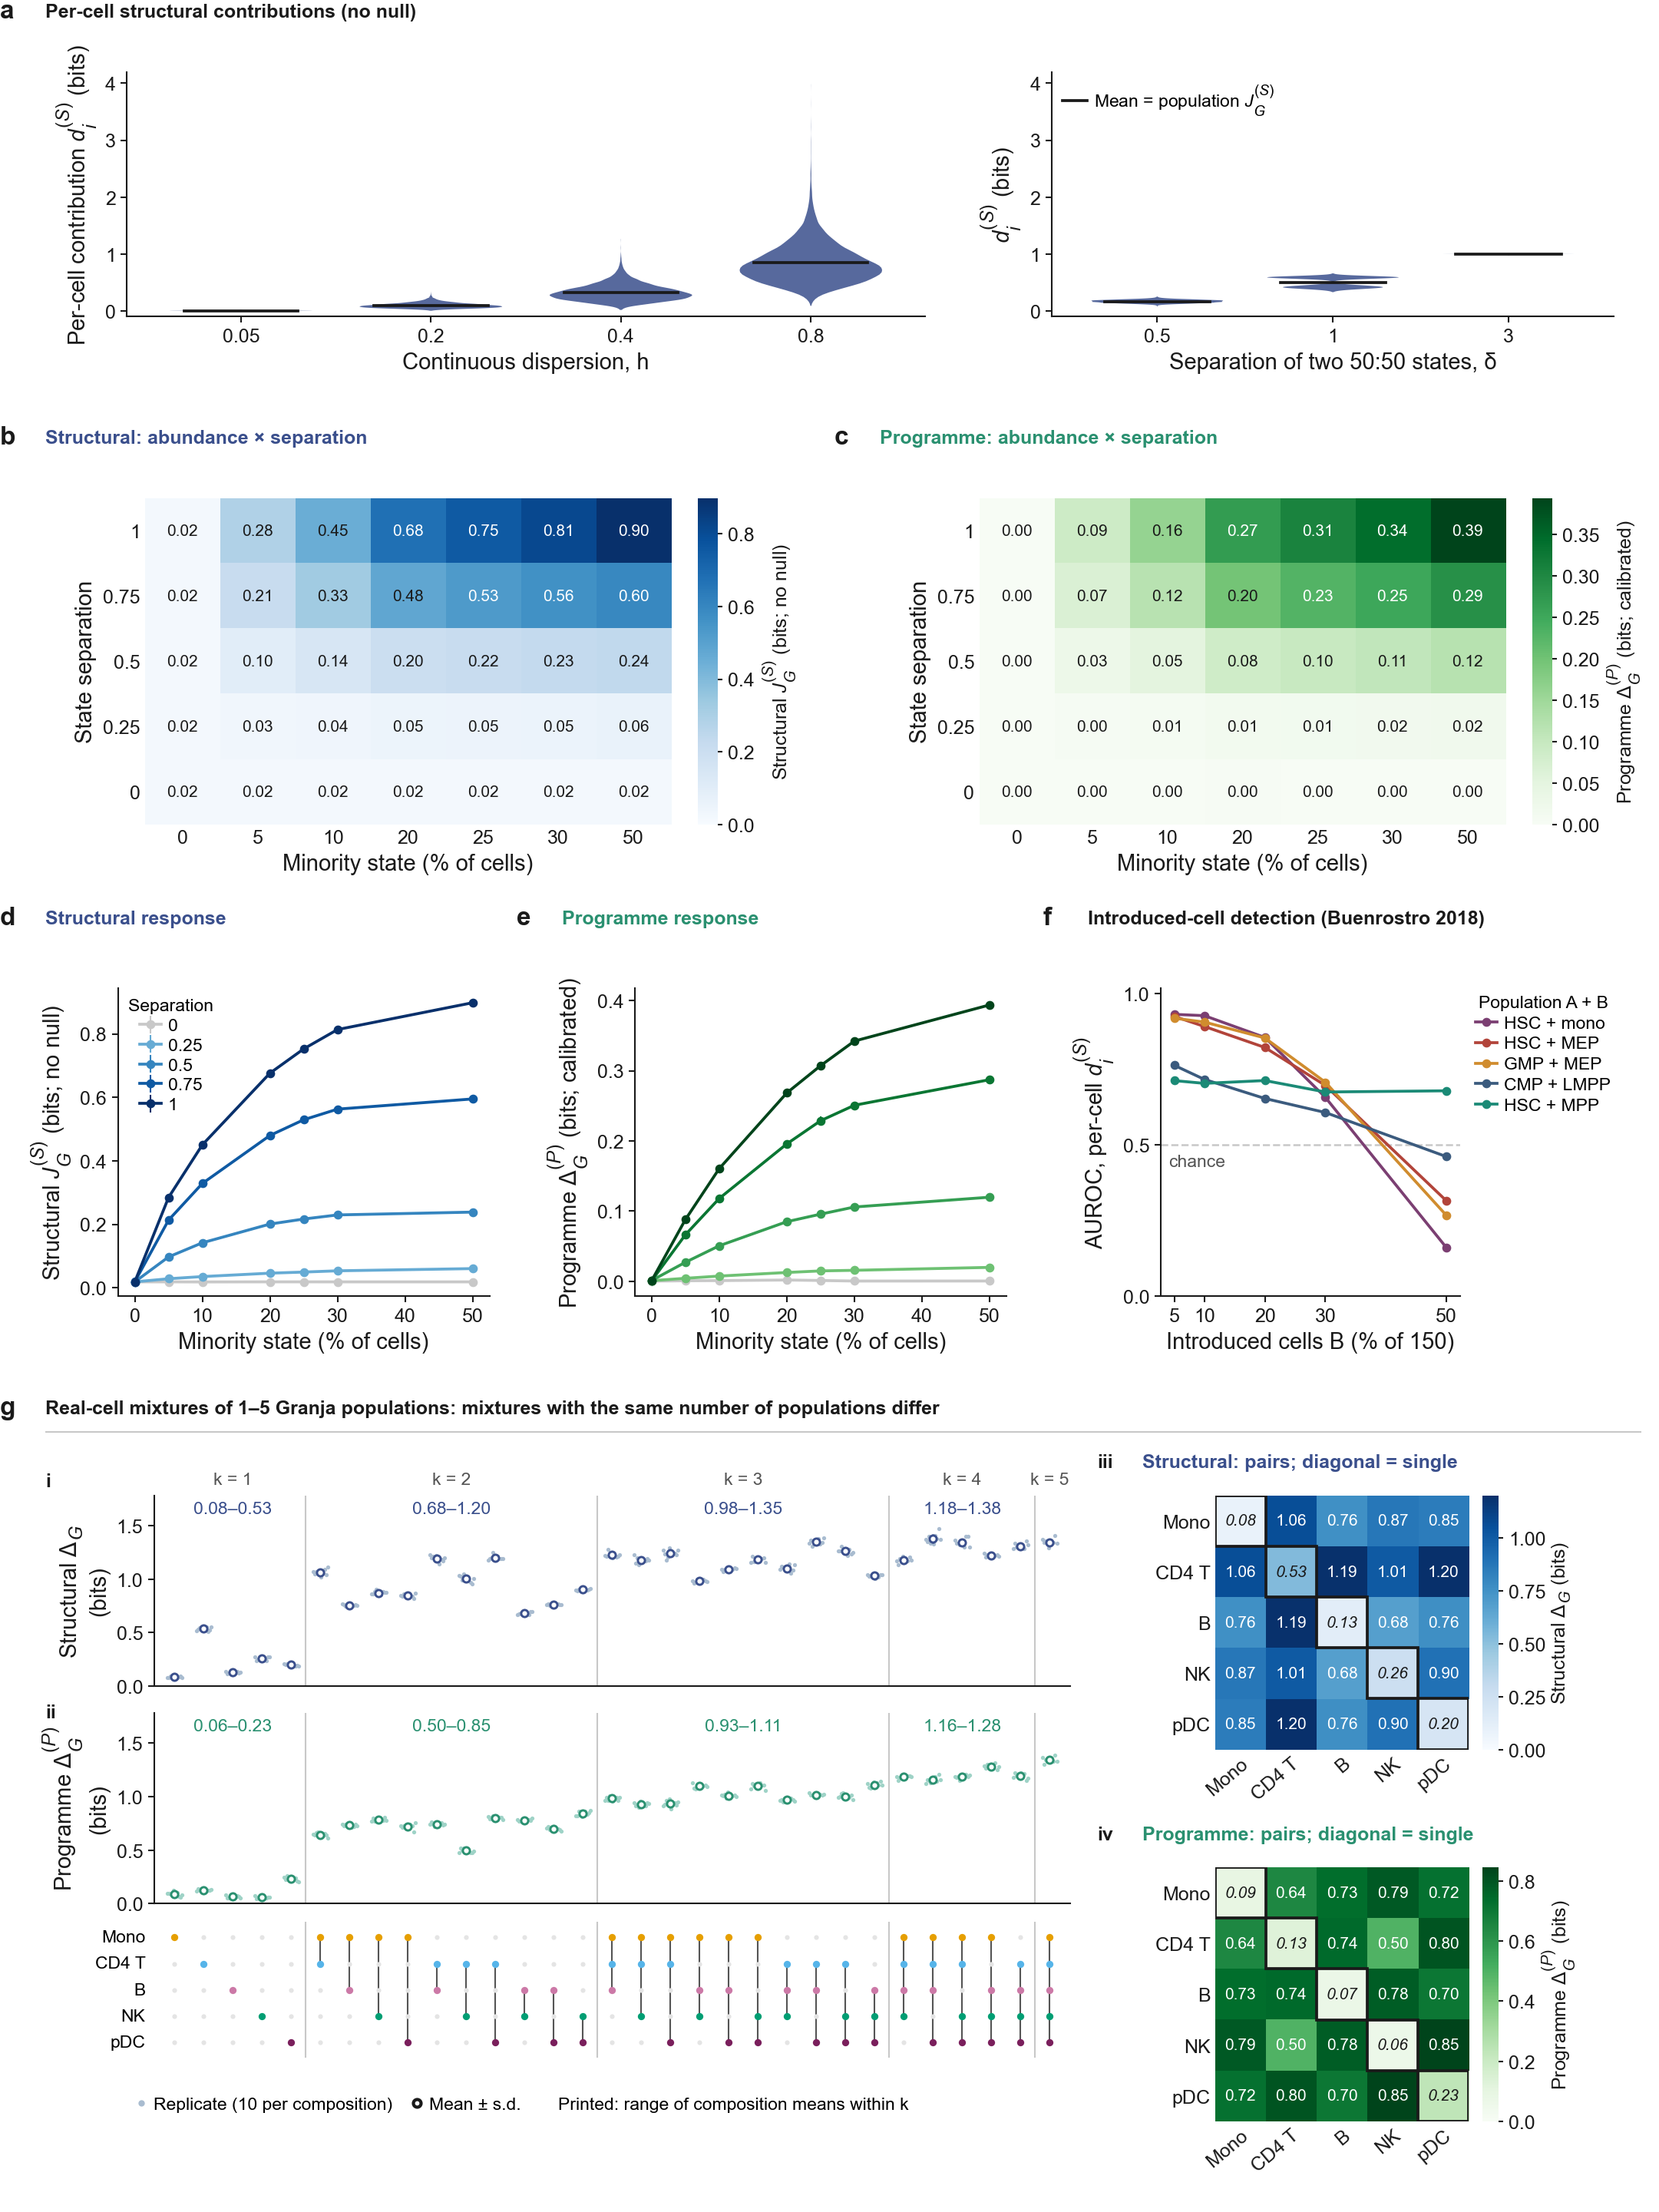

In [15]:
canvas = Canvas(*SIZE)
for letter, draw in (
    ("a", panel_a), ("b", panel_b), ("c", panel_c),
    ("d", panel_d), ("e", panel_e), ("f", panel_f), ("g", panel_g),
):
    x, y, _, _ = PANELS[letter]
    region = Region(canvas, x, y)
    draw(region)
    region.letter(letter)

save_figure(canvas.fig, "FigureS1")
display(Image(filename=str(FIG / "FigureS1.png")))
plt.close(canvas.fig)

## Supplementary Figure S2 — Technical robustness (s05)

Plots S2a–j from existing s05 technical-robustness and Granja result tables. No benchmark is recomputed here. The original S2 plotting cells are retained below.


In [ ]:
from pathlib import Path
from types import SimpleNamespace
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Work whether launched from the repository root or its notebooks/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").is_dir() and (ROOT.parent / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "results").is_dir(), "Open from scCHART_analysis/ or notebooks/"
FIG_ROOT = ROOT / "figures"
MM = 1 / 25.4
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = 8, 7, 6, 6, 5.5, 5
LW_AX, LW_DATA = 0.5, 1.0
STRUCT, STRUCT_L = "#3A4F8C", "#A9BCD0"
PROG, PROG_L = "#2A9070", "#9FD3C7"
EPI, JAC = "#C0632B", "#8C8C8C"
INK, MUTED, GUIDE = "#1A1A1A", "#555555", "#C8C8C8"
NEUTRAL_L = "#BDBDBD"

def apply_style() -> None:
    """Matplotlib settings of the frozen figures (Arial, 5-8 pt, editable text in SVG/PDF)."""
    import matplotlib._mathtext as mathtext
    mathtext.SHRINK_FACTOR = 0.84            # sub/superscripts of 6 pt text stay >= 5 pt
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"], "font.size": FS_TICK,
        "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold", "mathtext.sf": "Arial", "mathtext.default": "it",
        "axes.labelsize": FS_LABEL, "axes.titlesize": FS_LABEL, "axes.titlepad": 3,
        "axes.linewidth": LW_AX, "axes.edgecolor": INK, "axes.labelcolor": INK, "axes.labelpad": 2,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "xtick.major.width": LW_AX,
        "ytick.major.width": LW_AX, "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5,
        "ytick.major.pad": 1.5, "xtick.color": INK, "ytick.color": INK,
        "legend.fontsize": FS_ANN, "legend.frameon": False, "legend.handletextpad": 0.4,
        "legend.borderaxespad": 0.2, "legend.labelspacing": 0.25,
        "lines.linewidth": LW_DATA, "lines.markersize": 2.6, "errorbar.capsize": 0,
        "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
        "figure.facecolor": "white", "savefig.facecolor": "white",
    })

class Canvas:
    """A figure laid out in millimetres, origin at the top-left corner."""

    def __init__(self, width_mm: float, height_mm: float):
        import matplotlib.pyplot as plt
        self.fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
        # Matplotlib rounds the figure size to whole pixels (183 mm -> 7.2 in); positions are computed from the
        # realised size, as in the frozen figures, so element coordinates match them exactly.
        self.W, self.H = (v / MM for v in self.fig.get_size_inches())

    def ax(self, x, y, w, h, **kw):
        return self.fig.add_axes([x / self.W, 1 - (y + h) / self.H, w / self.W, h / self.H], **kw)

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", FS_ANN); kw.setdefault("va", "top"); kw.setdefault("color", INK)
        return self.fig.text(x / self.W, 1 - y / self.H, s, **kw)

    def letter(self, x, y, s):
        return self.text(x, y, s, fontsize=FS_LETTER, fontweight="bold", ha="left")

    def legend_at(self, handles, x, y, **kw):
        """Figure legend whose top centre is at (x, y) mm."""
        return self.fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x / self.W, 1 - y / self.H),
                               borderaxespad=0, **kw)

class Region:
    """A panel region of a Canvas: the same placement calls, in mm relative to the region's top-left corner."""

    def __init__(self, cv: Canvas, x0: float, y0: float):
        self.cv, self.x0, self.y0, self.fig = cv, x0, y0, cv.fig

    def ax(self, x, y, w, h, **kw):
        return self.cv.ax(self.x0 + x, self.y0 + y, w, h, **kw)

    def text(self, x, y, s, **kw):
        return self.cv.text(self.x0 + x, self.y0 + y, s, **kw)

    def letter(self, s):
        return self.cv.letter(self.x0, self.y0, s)

    def head(self, x, y, s, w=None, color=None, fontsize=None):
        """Bold section heading, optionally underlined by a guide rule of width w mm."""
        self.text(x, y, s, fontsize=fontsize or FS_ANN, fontweight="bold", color=color or INK)
        if w:
            a = self.ax(x, y + 3.4, w, 0.4); a.set_xlim(0, 1); a.set_ylim(0, 1); blank(a)
            a.plot([0, 1], [0.5, 0.5], c=GUIDE, lw=0.5)

def label(ax, s, **kw):
    """Plain left-aligned label above an axes."""
    ax.set_title(s, loc=kw.pop("loc", "left"), fontsize=kw.pop("fontsize", FS_ANN), color=INK, pad=kw.pop("pad", 2), **kw)

def halo(width=1.4):
    import matplotlib.patheffects as pe
    return [pe.withStroke(linewidth=width, foreground="white")]

def fmt_p(p, sym="P"):
    """P = 0.56, P = 0.015, P = 4.7 × 10⁻⁴ (mathtext superscript), as printed on the frozen figures."""
    import numpy as np
    if p >= 0.01:
        s = f"{p:.2f}" if p >= 0.1 else f"{p:#.2g}"
        return f"{sym} = {s}"
    e = int(np.floor(np.log10(p))); m = p / 10 ** e
    if round(m, 1) >= 10:
        m, e = m / 10, e + 1
    return f"{sym} = {m:.1f} × 10$^{{{e}}}$"

def short(g: str) -> str:
    """Granja population id -> display name ('01_HSC' -> 'HSC'; unannotated clusters -> 'Unk 13')."""
    return "Unk " + g.split("_")[0] if g.endswith("Unk") else g.split("_", 1)[1]

def blank(ax) -> None:
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# Manuscript source names -> directories in the public analysis repository.
RESULT_DIRS = {
    "01_synthetic_benchmarks": "01_benchmarks",
    "02_hematopoiesis": "02_granja",
    "03_CATLAS_programmes": "03_catlas",
    "04_xenograft_HSC": "04_hsc",
    "05_method_comparisons": "05_method_comparisons",
}

def result_path(rel):
    parts = Path(rel).parts
    if len(parts) >= 3 and parts[1] == "results":
        return ROOT / "results" / RESULT_DIRS.get(parts[0], parts[0]) / Path(*parts[2:])
    return ROOT / rel

def read(rel, cols=None, n_rows=None):
    path = result_path(rel)
    df = pd.read_csv(path, sep="\t")
    if cols:
        missing = set(cols) - set(df.columns)
        assert not missing, f"{path}: missing {sorted(missing)}"
    if n_rows is not None:
        assert len(df) == n_rows, f"{path}: {len(df)} rows, expected {n_rows}"
    return df

def printed(panel, quantity, exact, fmt, source, flag=False):
    # Format a value read from a result table; no frozen-manuscript comparisons.
    return fmt(exact) if callable(fmt) else (format(exact, fmt) if fmt else str(exact))

OUTPUT_DIR = FIG_ROOT / "02_granja"  # notebook section sets this explicitly.

def save(fig, name):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for ext, opts in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = OUTPUT_DIR / f"{name}.{ext}"
        fig.savefig(path, **opts)
        print(path.relative_to(ROOT))

def build(name, size_mm, panels):
    cv = Canvas(*size_mm)
    for letter, x, y, draw in panels:
        region = Region(cv, x, y)
        draw(region)
        if letter:
            region.letter(letter)
    save(cv.fig, name)
    return cv

fs = SimpleNamespace(**{k: globals()[k] for k in (
    "apply_style", "Canvas", "Region", "label", "halo", "fmt_p", "short", "blank",
    "read", "save", "build", "printed", "ROOT", "STRUCT", "STRUCT_L", "PROG", "PROG_L",
    "EPI", "JAC", "INK", "MUTED", "GUIDE", "NEUTRAL_L", "FS_LETTER", "FS_LABEL",
    "FS_TICK", "FS_ANN", "FS_SMALL", "FS_MIN")})
apply_style()


## Figure S2

**Technical robustness.** The full figure requires completed s05 result tables. This section is intentionally guarded: it must not run until all expected s05 tables and its run record exist.

**Deferred while s05 runs.** Run the following cells only after all s05 tables and its run JSON exist.

In [ ]:
OUTPUT_DIR = ROOT / "figures" / "01_benchmarks"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

import matplotlib.pyplot as plt
import numpy as np
SIZE = (183, 214)
PANELS = {"a": (0, 0, 60, 58), "b": (60, 0, 60, 58), "c": (122, 0, 61, 58), "d-g": (0, 62, 112, 88),
          "h": (115, 62, 68, 88), "i": (0, 154, 91, 60), "j": (92, 154, 91, 60)}
PANEL_REGIONS = PANELS
NULLC = "#8C8C8C"
R1, R2 = "01_synthetic_benchmarks/results/", "02_hematopoiesis/results/"
dep = fs.read(R1 + "robustness_depth_series_summary.tsv", ["median_depth_mean", "J_S_mean", "E0_S_mean", "Delta_S_mean",
                                                           "Delta_S_sd", "J_P_mean", "E0_P_mean", "Delta_P_mean", "Delta_P_sd"], 7)
md = fs.read(R1 + "robustness_matched_depth_comparison.tsv", ["population", "Delta_S_observed", "Delta_S_Dstar_mean",
                                                              "Delta_P_observed", "Delta_P_Dstar_mean", "D_star"], 2)
pop = fs.read(R2 + "granja_population_summary.tsv", ["population", "median_count_depth", "J_obs", "Delta_G_Dstar", "J_P_obs",
                                                     "Delta_P_Dstar", "D_star_structural"], 26).set_index("population")
nda = fs.read(R2 + "native_depth_associations.tsv", ["score", "spearman_rho", "p", "n"], 6).set_index("score")
dr = fs.read(R2 + "depth_series_summary.tsv", ["population", "level", "Delta_S", "Delta_P"], 40)
dr["level"] = dr.level.astype(str)
rk = fs.read(R2 + "depth_series_ranking_stability.tsv", ["axis", "estimator", "level", "kendall_tau_means"], 20)
rk["level"] = rk.level.astype(str)
cn = fs.read(R1 + "robustness_cell_number_summary.tsv", ["N", "Delta_S_mean", "Delta_S_sd", "Delta_P_mean", "Delta_P_sd"], 5)
LV = [250, 400, 789, 1200]
POPS8 = sorted(dr.population.unique())
assert len(POPS8) == 8
DSTAR = float(pop.D_star_structural.iloc[0])
S05 = __import__("json").loads((result_path(R1 + "s05_technical_robustness.run.json")).read_text())

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [ ]:
def fmt_p(p):
    """P formatting of the frozen Figure S2 (P = 0.61; P = 2.8 × 10⁻⁶)."""
    if p < 1e-3:
        m, e = f"{p:.1e}".split("e")
        return f"P = {float(m):.1f} × 10$^{{{int(e)}}}$"
    return f"P = {p:.2g}"

def thin(P, s, c, cl, lab, legend):
    ax = P.ax(12, 9, 42, 38)
    ax.plot(dep.median_depth_mean, dep[f"J_{s}_mean"], "-o", c=cl, ms=2.2, label="Observed $J$")
    ax.plot(dep.median_depth_mean, dep[f"E0_{s}_mean"], "--o", c=NULLC, ms=2.2, mfc="white", label="Null $E_0[J]$")
    ax.errorbar(dep.median_depth_mean, dep[f"Delta_{s}_mean"], yerr=dep[f"Delta_{s}_sd"], fmt="-o", c=c, ms=2.2,
                elinewidth=0.6, label="Excess Δ = $J - E_0[J]$")
    ax.set_xscale("log"); ax.set_xticks([300, 1000, 3000], ["300", "1,000", "3,000"]); ax.minorticks_off()
    ax.set(xlabel="Median counts per cell (thinned)", ylabel=f"{lab} score (bits)", ylim=(0, 1.6))
    ax.set_title(lab, loc="left", fontsize=FS_ANN, color=c, pad=2)
    if legend:
        ax.legend(fontsize=FS_SMALL, loc="upper right", handlelength=1.6)

### Panel a — Cell-level distributions

In [ ]:
def s05_gmp_n_cells(record):
    """Get the D1 GMP thinning cell count from the S05 run record, checking schema variants."""
    candidates = []

    def visit(obj, path=()):
        if isinstance(obj, dict):
            for key, value in obj.items():
                next_path = path + (str(key),)
                if str(key) in ("n_cells", "n_gmp_cells", "n_cells_gmp") and isinstance(value, (int, float)):
                    if float(value).is_integer() and value > 0:
                        candidates.append((next_path, int(value)))
                visit(value, next_path)
        elif isinstance(obj, list):
            for i, value in enumerate(obj):
                visit(value, path + (str(i),))

    visit(record)
    d1 = [(p, v) for p, v in candidates if "D1" in p or "d1" in p]
    selected = d1 if d1 else candidates
    unique = {v for _, v in selected}
    if len(unique) == 1:
        return unique.pop()
    if not selected:
        raise ValueError("S05 run record has no numerical n_cells field; inspect results/01_benchmarks/s05_technical_robustness.run.json")
    raise ValueError(f"Ambiguous S05 cell-count fields: {selected}. Determine the D1 GMP cell count from s05 script before plotting.")


In [ ]:
def panel_a(P):
    n = printed("a", "GMP cells thinned", 1000, ",d",
                R1 + "s05_technical_robustness.py (depth-downsampling design: 1,000 GMP cells)")
    P.head(5, 0.4, f"Controlled thinning ({n} GMP cells)", w=112)
    thin(P, "S", STRUCT, STRUCT_L, "Structural", True)

### Panel b — Population-level rankings

In [ ]:
def panel_b(P): thin(P, "P", PROG, PROG_L, "Programme", False)

### Panel c — Association or state composition

In [ ]:
def panel_c(P):
    P.head(5, 0.4, "Depth-thinned GMP control", w=56)
    ax = P.ax(12, 9, 40, 38)
    x = np.arange(2); w = 0.19
    for j, (col, lab, c) in enumerate((("Delta_S_observed", "Structural Δ, as observed", STRUCT_L),
                                       ("Delta_S_Dstar_mean", "Structural Δ(D*)", STRUCT),
                                       ("Delta_P_observed", "Programme Δ, as observed", PROG_L),
                                       ("Delta_P_Dstar_mean", "Programme Δ(D*)", PROG))):
        ax.bar(x + (j - 1.5) * w, md[col], w * 0.92, color=c, label=lab)
    ax.set_xticks(x, ["GMP", "GMP after artificial\ndepth thinning"])
    ax.set(ylabel="Calibrated excess (bits)", ylim=(0, 1.12), yticks=[0, 0.5, 1])
    ax.legend(fontsize=FS_MIN, ncol=2, loc="upper left", columnspacing=0.6, handlelength=0.9)
    assert md.D_star.nunique() == 1
    D = printed("c", "D* of the control (counts)", float(md.D_star.iloc[0]), ",.1f", R1 + "robustness_matched_depth_comparison.tsv")
    fs.label(ax, f"D* = {D} counts (this control)", fontsize=FS_MIN)

### Panel dg — Manuscript display

In [ ]:
def panel_dg(P):
    n = printed("d-g", "populations", len(pop), "d", R2 + "granja_population_summary.tsv")
    P.head(5, 0.4, f"Association with native depth across {n} Granja populations", w=108)
    P.text(31, 5.6, "Raw heterogeneity", ha="center", fontsize=FS_ANN)
    P.text(82, 5.6, "Calibrated, matched-depth Δ(D*)", ha="center", fontsize=FS_ANN)
    P.text(1.5, 25, "Structural", rotation=90, va="center", fontsize=FS_ANN, color=STRUCT, fontweight="bold")
    P.text(1.5, 64, "Programme", rotation=90, va="center", fontsize=FS_ANN, color=PROG, fontweight="bold")
    specs = [("d", 16, 11, "J_obs", STRUCT_L, "$J_G^{(S)}$ (bits)", "Spearman native depth vs J_S"),
             ("e", 67, 11, "Delta_G_Dstar", STRUCT, "$Δ_G$(D*) (bits)", "Spearman native depth vs Delta_G(D*)"),
             ("f", 16, 50, "J_P_obs", PROG_L, "$J_G^{(P)}$ (bits)", "Spearman native depth vs J_P"),
             ("g", 67, 50, "Delta_P_Dstar", PROG, "$Δ_G^{(P)}$(D*) (bits)", "Spearman native depth vs Delta_P(D*)")]
    for L, x0, y0, col, c, yl, q in specs:
        ax = P.ax(x0, y0, 30, 26)
        ax.scatter(pop.median_count_depth, pop[col], s=6, c=c, lw=0)
        ax.set_xscale("log"); ax.set_xticks([1000, 3000], ["1,000", "3,000"]); ax.minorticks_off()
        ax.set_ylabel(yl)
        r = nda.loc[col]
        txt = printed(L, q, (float(r.spearman_rho), float(r.p)), lambda v: f"ρ = {v[0]:.2f}, {fmt_p(v[1])}",
                      R2 + "native_depth_associations.tsv")
        ax.text(0.03, 0.97, txt.replace(", P", "\nP"), transform=ax.transAxes, va="top", fontsize=FS_SMALL)
        ax.set_xlabel("Native median counts", fontsize=FS_ANN)
        P.text(x0 - 12, y0 - 2.5, L, fontsize=FS_LETTER, fontweight="bold")

### Panel h — Robustness analysis

In [ ]:
def panel_h(P):
    D = printed("h", "D* (counts)", DSTAR, ".0f", R2 + "granja_population_summary.tsv")
    P.head(5, 0.4, f"Fixed populations thinned to common depths (D* = {D})", w=70)
    HIGHLIGHT = ("07_GMP", "24_CD8.CM")
    printed("h", "highlighted programme populations", ", ".join(sorted(fs.short(p) for p in HIGHLIGHT)), "",
            "frozen design (labelled populations)")
    for k, (s_, lab, c, cl) in enumerate((("S", "Structural", STRUCT, STRUCT_L), ("P", "Programme", PROG, PROG_L))):
        ax = P.ax(14, 10 + k * 39, 44, 26)
        for pp in POPS8:
            d = dr[dr.population == pp].set_index("level")
            nat = float(d.loc["native", f"Delta_{s_}"])
            y = [float(d.loc[str(L), f"Delta_{s_}"]) / nat for L in LV]
            hl = s_ == "P" and pp in HIGHLIGHT
            ax.plot(LV, y, "-o", c=c if hl else cl, ms=1.8, lw=1.0 if hl else 0.6, zorder=3 if hl else 2)
            if hl:
                ax.text(1330, y[-1], fs.short(pp), fontsize=FS_SMALL, va="center")
        ax.axhline(1, c=GUIDE, lw=0.5, ls=":"); ax.axvline(DSTAR, c=INK, lw=0.6, ls="--")
        ax.text(DSTAR * 0.97, 0.2, "D*", ha="right", fontsize=FS_SMALL)
        ax.set_xscale("log"); ax.set_xticks(LV, ["250", "400", "789", "1,200"]); ax.minorticks_off()
        ax.set(ylim=(0.15, 1.12), yticks=[0.2, 0.6, 1.0], ylabel="Δ / native Δ")
        ax.set_xlabel("Common depth (counts)", fontsize=FS_ANN)
        ax.set_title(lab, loc="left", fontsize=FS_ANN, color=c, pad=2)

### Panel i — Ranking stability

In [ ]:
def panel_i(P):
    P.head(5, 0.4, "Ranking stability (8 fixed populations)", w=80)
    ax = P.ax(14, 9, 44, 34)
    X = ["250", "400", "789", "native"]
    for axis, est, c, ls, lab in (("P", "Delta_P", PROG, "-", "Programme Δ"), ("P", "J_P", PROG_L, "--", "Programme raw $J$"),
                                  ("S", "Delta_S", STRUCT, "-", "Structural Δ"), ("S", "J_S", STRUCT_L, "--", "Structural raw $J$")):
        d = rk[(rk.axis == axis) & (rk.estimator == est)].set_index("level").loc[X]
        ax.plot(range(4), d.kendall_tau_means, ls=ls, marker="o", c=c, ms=2, label=lab)
    ax.axvline(2, c=INK, lw=0.6, ls="--"); ax.text(2.08, 0.76, "D*", fontsize=FS_SMALL)
    ax.set_xticks(range(4), X)
    ax.set(ylim=(0.1, 1.05), xlabel="Common depth (counts)", ylabel="Kendall τ vs reference order")
    ax.legend(fontsize=FS_SMALL, loc="lower left", handlelength=1.6, borderaxespad=0.1)
    fs.label(ax, "Reference: Δ order at 1,200 counts", fontsize=FS_SMALL)

### Panel j — Population-size sensitivity

In [ ]:
def panel_j(P):
    P.head(5, 0.4, "Population size (GMP subsamples, native depth)", w=80)
    ax = P.ax(14, 9, 44, 34)
    ax.errorbar(cn.N, cn.Delta_S_mean, yerr=cn.Delta_S_sd, fmt="-o", c=STRUCT, ms=2.2, elinewidth=0.6, label="Structural $Δ_G$")
    ax.errorbar(cn.N, cn.Delta_P_mean, yerr=cn.Delta_P_sd, fmt="-o", c=PROG, ms=2.2, elinewidth=0.6, label="Programme $Δ_G^{(P)}$")
    ax.set_xscale("log"); ax.set_xticks([100, 250, 500, 1000, 2000], ["100", "250", "500", "1,000", "2,000"]); ax.minorticks_off()
    ax.set(xlabel="Cells in declared population", ylabel="Calibrated excess (bits)", ylim=(0, 0.85))
    ax.legend(fontsize=FS_SMALL, loc="lower right")

### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

In [ ]:
from IPython.display import display, Image
cv = build("FigureS2", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c),('d-g',PANELS['d-g'][0],PANELS['d-g'][1],panel_dg),('h',PANELS['h'][0],PANELS['h'][1],panel_h),('i',PANELS['i'][0],PANELS['i'][1],panel_i),('j',PANELS['j'][0],PANELS['j'][1],panel_j)])
display(Image(filename=str(OUTPUT_DIR / "FigureS2.png")))
plt.close(cv.fig)